In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [2]:
# Load the dataset into a pandas DataFrame
dataset = pd.read_csv("GN_population_excel.csv",header=[3,4])


# Display the first 5 rows to understand the structure
dataset.head()

,Province\nCode,Province\nName,District\nCode,District\nName,DS_Division\nCode,DS_Division\nName,GN_Division\nCode,GN_Division\nName,GN_Division\nNumber,Sex,Unnamed: 10_level_0,Unnamed: 11_level_0,Age_Group,Unnamed: 13_level_0,Unnamed: 14_level_0,Unnamed: 15_level_0,Unnamed: 16_level_0
,Unnamed: 0_level_1,Unnamed: 1_level_1,Unnamed: 2_level_1,Unnamed: 3_level_1,Unnamed: 4_level_1,Unnamed: 5_level_1,Unnamed: 6_level_1,Unnamed: 7_level_1,Unnamed: 8_level_1,Total,Male,Female,Total,0 - 14,15 - 59,60 - 64,65 and above
0,1.0,Western,11.0,Colombo,3.0,Colombo,5.0,Sammanthranapura,,"7,640","3,864","3,776","7,640","1,695","4,891",393,661
1,1.0,Western,11.0,Colombo,3.0,Colombo,10.0,Mattakkuliya,,"28,135","13,749","14,386","28,135","5,653","18,163","1,499","2,820"
2,1.0,Western,11.0,Colombo,3.0,Colombo,15.0,Modara,,"31,728","15,579","16,149","31,728","6,930","20,400","1,554","2,844"
3,1.0,Western,11.0,Colombo,3.0,Colombo,20.0,Madampitiya,,"7,699","3,890","3,809","7,699","1,831","5,024",353,491
4,1.0,Western,11.0,Colombo,3.0,Colombo,25.0,Mahawatta,,"7,108","3,611","3,497","7,108","1,504","4,582",354,668


In [3]:
# Rename the columns with meaningful names
dataset.columns = [
    'Province_Code',
    'Province_Name',
    'District_Code',
    'District_Name',
    'DS_Division_Code',
    'DS_Division_Name',
    'GN_Division_Code',
    'GN_Division_Name',
    'GN_Division_Number',
    'Sex_Total',
    'Male_Population',
    'Female_Population',
    'Total_Age_Group',
    'Age_0_14',
    'Age_15_59',
    'Age_60_64',
    'Age_65_Plus'
]

# Display the first 5 rows
dataset.head()

,Province_Code,Province_Name,District_Code,District_Name,DS_Division_Code,DS_Division_Name,GN_Division_Code,GN_Division_Name,GN_Division_Number,Sex_Total,Male_Population,Female_Population,Total_Age_Group,Age_0_14,Age_15_59,Age_60_64,Age_65_Plus
0,1.0,Western,11.0,Colombo,3.0,Colombo,5.0,Sammanthranapura,,"7,640","3,864","3,776","7,640","1,695","4,891",393,661
1,1.0,Western,11.0,Colombo,3.0,Colombo,10.0,Mattakkuliya,,"28,135","13,749","14,386","28,135","5,653","18,163","1,499","2,820"
2,1.0,Western,11.0,Colombo,3.0,Colombo,15.0,Modara,,"31,728","15,579","16,149","31,728","6,930","20,400","1,554","2,844"
3,1.0,Western,11.0,Colombo,3.0,Colombo,20.0,Madampitiya,,"7,699","3,890","3,809","7,699","1,831","5,024",353,491
4,1.0,Western,11.0,Colombo,3.0,Colombo,25.0,Mahawatta,,"7,108","3,611","3,497","7,108","1,504","4,582",354,668


In [4]:
dataset.tail()

,Province_Code,Province_Name,District_Code,District_Name,DS_Division_Code,DS_Division_Name,GN_Division_Code,GN_Division_Name,GN_Division_Number,Sex_Total,Male_Population,Female_Population,Total_Age_Group,Age_0_14,Age_15_59,Age_60_64,Age_65_Plus
14004,9.0,Sabaragamuwa,92.0,Kegalle,33.0,Deraniyagala,115.0,Kosgahakanda,113A,"2,238","1,088","1,150","2,238",441,"1,277",169,351
14005,9.0,Sabaragamuwa,92.0,Kegalle,33.0,Deraniyagala,120.0,Yatiwala,113B,"1,727",866,861,"1,727",337,"1,050",91,249
14006,9.0,Sabaragamuwa,92.0,Kegalle,33.0,Deraniyagala,125.0,Magala,113,947,478,469,947,160,562,55,170
14007,9.0,Sabaragamuwa,92.0,Kegalle,33.0,Deraniyagala,130.0,Dikellakanda,112E,555,292,263,555,87,332,49,87
14008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Display information about the dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 14009 entries, 0 to 14008
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Province_Code       14008 non-null  float64
 1   Province_Name       14008 non-null  str    
 2   District_Code       14008 non-null  float64
 3   District_Name       14008 non-null  str    
 4   DS_Division_Code    14008 non-null  float64
 5   DS_Division_Name    14008 non-null  str    
 6   GN_Division_Code    14008 non-null  float64
 7   GN_Division_Name    14008 non-null  str    
 8   GN_Division_Number  14008 non-null  str    
 9   Sex_Total           14008 non-null  str    
 10  Male_Population     14008 non-null  str    
 11  Female_Population   14008 non-null  str    
 12  Total_Age_Group     14008 non-null  str    
 13  Age_0_14            14008 non-null  str    
 14  Age_15_59           14008 non-null  str    
 15  Age_60_64           14008 non-null  str    
 16  Age_65_Plus    

In [6]:
# Display the number of rows and columns
print(dataset.shape)

(14009, 17)


In [7]:
# Check the number of missing values in each column
print(dataset.isna().sum())

Province_Code         1
Province_Name         1
District_Code         1
District_Name         1
DS_Division_Code      1
DS_Division_Name      1
GN_Division_Code      1
GN_Division_Name      1
GN_Division_Number    1
Sex_Total             1
Male_Population       1
Female_Population     1
Total_Age_Group       1
Age_0_14              1
Age_15_59             1
Age_60_64             1
Age_65_Plus           1
dtype: int64


In [8]:
# Check the number of duplicate records
print(dataset.duplicated().sum())

0


## Data Cleaning

In [9]:
# Remove rows with missing values
dataset = dataset.dropna()

# Display the number of rows and columns after removing missing values
print(dataset.shape)

(14008, 17)


In [10]:
# Display the data types of each column
print(dataset.dtypes)

Province_Code         float64
Province_Name             str
District_Code         float64
District_Name             str
DS_Division_Code      float64
DS_Division_Name          str
GN_Division_Code      float64
GN_Division_Name          str
GN_Division_Number        str
Sex_Total                 str
Male_Population           str
Female_Population         str
Total_Age_Group           str
Age_0_14                  str
Age_15_59                 str
Age_60_64                 str
Age_65_Plus               str
dtype: object


In [11]:
# Display the current column names
print(dataset.columns)

Index(['Province_Code', 'Province_Name', 'District_Code', 'District_Name',
       'DS_Division_Code', 'DS_Division_Name', 'GN_Division_Code',
       'GN_Division_Name', 'GN_Division_Number', 'Sex_Total',
       'Male_Population', 'Female_Population', 'Total_Age_Group', 'Age_0_14',
       'Age_15_59', 'Age_60_64', 'Age_65_Plus'],
      dtype='str')


In [12]:
# Rename the columns with meaningful names
dataset.columns = [
    'Province_Code',
    'Province_Name',
    'District_Code',
    'District_Name',
    'DS_Division_Code',
    'DS_Division_Name',
    'GN_Division_Code',
    'GN_Division_Name',
    'GN_Division_Number',
    'Total_Population',
    'Male_Population',
    'Female_Population',
    'Age_Total',
    'Age_0_14',
    'Age_15_59',
    'Age_60_64',
    'Age_65_Plus'
]

# Display the column names after renaming
print(dataset.columns)

Index(['Province_Code', 'Province_Name', 'District_Code', 'District_Name',
       'DS_Division_Code', 'DS_Division_Name', 'GN_Division_Code',
       'GN_Division_Name', 'GN_Division_Number', 'Total_Population',
       'Male_Population', 'Female_Population', 'Age_Total', 'Age_0_14',
       'Age_15_59', 'Age_60_64', 'Age_65_Plus'],
      dtype='str')


In [13]:
# Convert population columns to numeric data types
population_columns = [
    'Total_Population',
    'Male_Population',
    'Female_Population',
    'Age_Total',
    'Age_0_14',
    'Age_15_59',
    'Age_60_64',
    'Age_65_Plus'
]

# Remove commas and extra spaces from population values
for column in population_columns:
    dataset[column] = (
        dataset[column]
        .astype(str)
        .str.replace(',', '')
        .str.strip()
        .replace('-', '0')
    )

# Convert population columns to numeric
dataset[population_columns] = dataset[population_columns].apply(pd.to_numeric)

# Display the data types after conversion
print(dataset.dtypes)

Province_Code         float64
Province_Name             str
District_Code         float64
District_Name             str
DS_Division_Code      float64
DS_Division_Name          str
GN_Division_Code      float64
GN_Division_Name          str
GN_Division_Number        str
Total_Population        int64
Male_Population         int64
Female_Population       int64
Age_Total               int64
Age_0_14                int64
Age_15_59               int64
Age_60_64               int64
Age_65_Plus             int64
dtype: object


In [14]:
# Check whether any population values are negative
print((dataset[population_columns] < 0).sum())

Total_Population     0
Male_Population      0
Female_Population    0
Age_Total            0
Age_0_14             0
Age_15_59            0
Age_60_64            0
Age_65_Plus          0
dtype: int64


In [15]:
# Check whether total population is equal to male population plus female population
dataset['Population_Check'] = (
    dataset['Male_Population'] + dataset['Female_Population']
)

print(
    (dataset['Total_Population'] != dataset['Population_Check']).sum()
)

0


In [16]:
# Remove the temporary checking column
dataset = dataset.drop('Population_Check', axis=1)

In [17]:
# Check whether the age groups add up to the age total
dataset['Age_Check'] = (
    dataset['Age_0_14']
    + dataset['Age_15_59']
    + dataset['Age_60_64']
    + dataset['Age_65_Plus']
)

print(
    (dataset['Age_Total'] != dataset['Age_Check']).sum()
)

0


In [18]:
# Remove the temporary checking column
dataset = dataset.drop('Age_Check', axis=1)

In [19]:
# Display the first 5 rows of the cleaned dataset
dataset.head()

,Province_Code,Province_Name,District_Code,District_Name,DS_Division_Code,DS_Division_Name,GN_Division_Code,GN_Division_Name,GN_Division_Number,Total_Population,Male_Population,Female_Population,Age_Total,Age_0_14,Age_15_59,Age_60_64,Age_65_Plus
0,1.0,Western,11.0,Colombo,3.0,Colombo,5.0,Sammanthranapura,,7640,3864,3776,7640,1695,4891,393,661
1,1.0,Western,11.0,Colombo,3.0,Colombo,10.0,Mattakkuliya,,28135,13749,14386,28135,5653,18163,1499,2820
2,1.0,Western,11.0,Colombo,3.0,Colombo,15.0,Modara,,31728,15579,16149,31728,6930,20400,1554,2844
3,1.0,Western,11.0,Colombo,3.0,Colombo,20.0,Madampitiya,,7699,3890,3809,7699,1831,5024,353,491
4,1.0,Western,11.0,Colombo,3.0,Colombo,25.0,Mahawatta,,7108,3611,3497,7108,1504,4582,354,668


In [20]:
# Display the shape of the cleaned dataset
print(dataset.shape)

(14008, 17)


In [21]:
# Check for missing values after cleaning
print(dataset.isna().sum())

Province_Code         0
Province_Name         0
District_Code         0
District_Name         0
DS_Division_Code      0
DS_Division_Name      0
GN_Division_Code      0
GN_Division_Name      0
GN_Division_Number    0
Total_Population      0
Male_Population       0
Female_Population     0
Age_Total             0
Age_0_14              0
Age_15_59             0
Age_60_64             0
Age_65_Plus           0
dtype: int64


In [22]:
# Check for duplicate records after cleaning
print(dataset.duplicated().sum())

0


## Statistical Summary

In [23]:
# Display the statistical summary of numerical columns
dataset.describe()

,Province_Code,District_Code,DS_Division_Code,GN_Division_Code,Total_Population,Male_Population,Female_Population,Age_Total,Age_0_14,Age_15_59,Age_60_64,Age_65_Plus
count,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000,14008.000000
mean,4.258210,44.285979,25.441391,141.225443,1554.954312,750.452884,804.501428,1554.954312,321.733224,953.300757,84.473872,195.446459
std,2.590258,25.682967,17.664690,118.056883,1307.983874,635.841454,674.869709,1307.983874,276.081350,837.690399,70.108736,158.011662
min,1.000000,11.000000,2.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,21.000000,12.000000,55.000000,821.000000,396.000000,424.000000,821.000000,166.000000,490.000000,46.000000,106.000000
50%,4.000000,41.000000,24.000000,115.000000,1201.000000,579.000000,623.000000,1201.000000,248.000000,725.000000,67.000000,156.000000
75%,6.000000,62.000000,36.000000,190.000000,1841.000000,888.000000,957.000000,1841.000000,387.250000,1126.000000,100.000000,231.000000
max,9.000000,92.000000,87.000000,755.000000,31728.000000,15579.000000,16149.000000,31728.000000,6930.000000,20400.000000,1554.000000,2844.000000


In [24]:
# Display the unique values in the Province Name column
print(dataset['Province_Name'].unique())

<StringArray>
[      'Western',       'Central',      'Southern',      'Northern',
       'Eastern', 'North Western', 'North Central',           'Uva',
  'Sabaragamuwa']
Length: 9, dtype: str


In [25]:
# Display the number of unique provinces
print(dataset['Province_Name'].nunique())

9


In [26]:
# Display the number of unique districts
print(dataset['District_Name'].nunique())

25


In [27]:
# Display the number of unique GN divisions
print(dataset['GN_Division_Name'].nunique())

12418


## Exploratory Data Analysis (EDA)

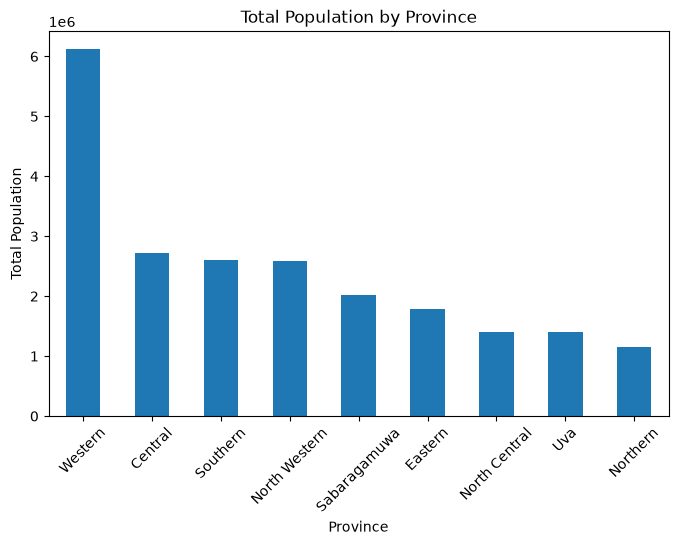

In [28]:
# Calculate the total population of each province
province_population = dataset.groupby('Province_Name')['Total_Population'].sum()

# Sort the values from highest to lowest
province_population = province_population.sort_values(ascending=False)

# Create a bar chart
plt.figure(figsize=(8, 5))
province_population.plot(kind='bar')

# Add title and labels
plt.title('Total Population by Province')
plt.xlabel('Province')
plt.ylabel('Total Population')

# Rotate the province names
plt.xticks(rotation=45)

# Display the chart
plt.show()

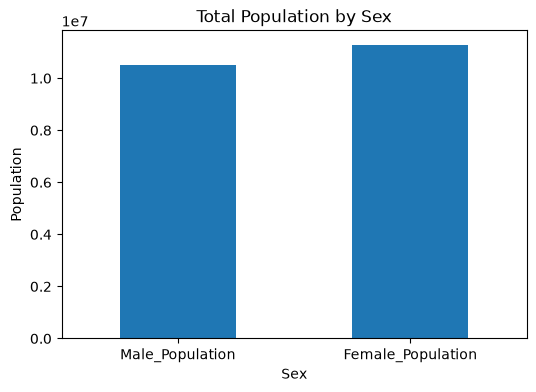

In [29]:
# Calculate the total male and female population
gender_population = dataset[
    ['Male_Population', 'Female_Population']
].sum()

# Create a bar chart
plt.figure(figsize=(6, 4))
gender_population.plot(kind='bar')

# Add title and labels
plt.title('Total Population by Sex')
plt.xlabel('Sex')
plt.ylabel('Population')

plt.xticks(rotation=0)


# Display the chart
plt.show()

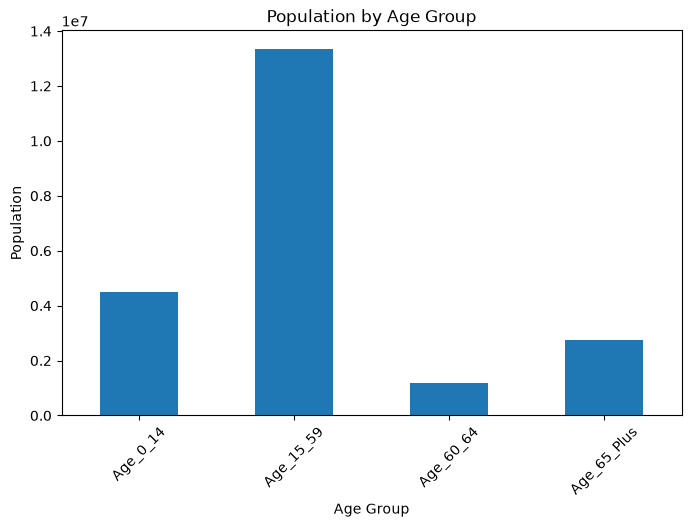

In [30]:
# Calculate the total population for each age group
age_population = dataset[
    ['Age_0_14', 'Age_15_59', 'Age_60_64', 'Age_65_Plus']
].sum()

# Create a bar chart
plt.figure(figsize=(8, 5))
age_population.plot(kind='bar')

# Add title and labels
plt.title('Population by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Population')

plt.xticks(rotation=45)


# Display the chart
plt.show()

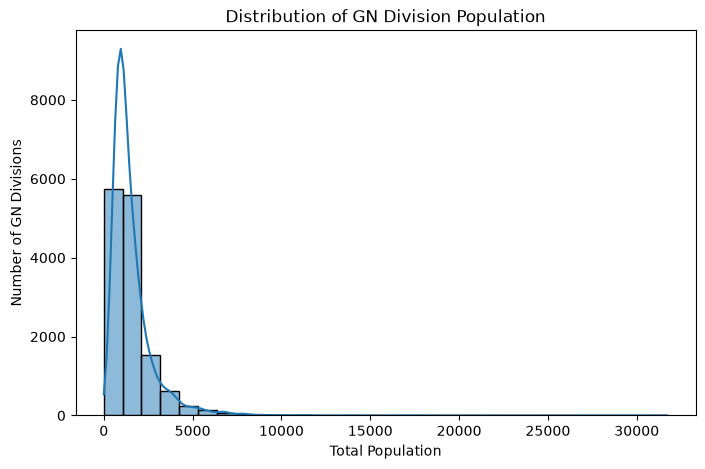

In [31]:
# Create a histogram of GN Division population
plt.figure(figsize=(8, 5))

sns.histplot(
    dataset['Total_Population'],
    bins=30,
    kde=True
)

# Add title and labels
plt.title('Distribution of GN Division Population')
plt.xlabel('Total Population')
plt.ylabel('Number of GN Divisions')

# Display the chart
plt.show()

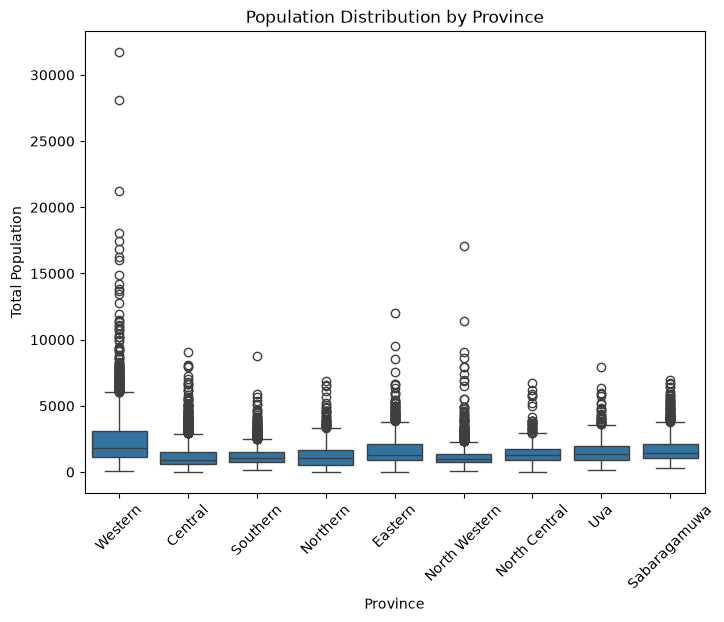

In [32]:
# Create a box plot to compare population distribution by province
plt.figure(figsize=(8,6))

sns.boxplot(
    x='Province_Name',
    y='Total_Population',
    data=dataset
)

# Add title and labels
plt.title('Population Distribution by Province')
plt.xlabel('Province')
plt.ylabel('Total Population')

# Rotate province names
plt.xticks(rotation=45)

# Display the chart
plt.show()

## Hypothesis Testing

In [33]:
# Perform a paired t-test between male and female population
t_statistic, p_value = stats.ttest_rel(
    dataset['Male_Population'],
    dataset['Female_Population']
)

# Display the test results
print("T-statistic:", t_statistic)
print("P-value:", p_value)

T-statistic: -68.72017076821393
P-value: 0.0


In [34]:
# Set the significance level
alpha = 0.05

# Compare the p-value with the significance level
if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant difference between male and female population.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference between male and female population.")

Reject the null hypothesis.
There is a significant difference between male and female population.


In [35]:
# Create population groups for each province
province_groups = []

for province in dataset['Province_Name'].unique():
    province_data = dataset[
        dataset['Province_Name'] == province
    ]['Total_Population']
    
    province_groups.append(province_data)

In [36]:
# Perform one-way ANOVA
f_statistic, p_value_anova = stats.f_oneway(*province_groups)

# Display the test results
print("F-statistic:", f_statistic)
print("P-value:", p_value_anova)

F-statistic: 240.86452525493138
P-value: 0.0


In [37]:
# Set the significance level
alpha = 0.05

# Compare the p-value with the significance level
if p_value_anova < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant difference in population between provinces.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in population between provinces.")

Reject the null hypothesis.
There is a significant difference in population between provinces.


## Hypothesis Testing Results

In [38]:
# Create a summary of the hypothesis testing results
hypothesis_results = pd.DataFrame({
    'Test': [
        'Paired t-test: Male vs Female',
        'One-way ANOVA: Population by Province'
    ],
    'Test Statistic': [
        t_statistic,
        f_statistic
    ],
    'P-value': [
        p_value,
        p_value_anova
    ]
})

# Display the results
hypothesis_results

,Test,Test Statistic,P-value
0,Paired t-test: Male vs Female,-68.720171,0.0
1,One-way ANOVA: Population by Province,240.864525,0.0


## Data Preprocessing

In [39]:
# Create a copy of the cleaned dataset
ml_dataset = dataset.copy()

# Display the first 5 rows
ml_dataset.head()

,Province_Code,Province_Name,District_Code,District_Name,DS_Division_Code,DS_Division_Name,GN_Division_Code,GN_Division_Name,GN_Division_Number,Total_Population,Male_Population,Female_Population,Age_Total,Age_0_14,Age_15_59,Age_60_64,Age_65_Plus
0,1.0,Western,11.0,Colombo,3.0,Colombo,5.0,Sammanthranapura,,7640,3864,3776,7640,1695,4891,393,661
1,1.0,Western,11.0,Colombo,3.0,Colombo,10.0,Mattakkuliya,,28135,13749,14386,28135,5653,18163,1499,2820
2,1.0,Western,11.0,Colombo,3.0,Colombo,15.0,Modara,,31728,15579,16149,31728,6930,20400,1554,2844
3,1.0,Western,11.0,Colombo,3.0,Colombo,20.0,Madampitiya,,7699,3890,3809,7699,1831,5024,353,491
4,1.0,Western,11.0,Colombo,3.0,Colombo,25.0,Mahawatta,,7108,3611,3497,7108,1504,4582,354,668


In [40]:
# Define the target variable
y = ml_dataset['Age_65_Plus']

# Define the features
x = ml_dataset[
    [
        'Province_Name',
        'District_Name',
        'DS_Division_Name',
        'GN_Division_Name',
        'Age_0_14',
        'Age_15_59',
        'Age_60_64'
    ]
]

# Display the features
x.head()

,Province_Name,District_Name,DS_Division_Name,GN_Division_Name,Age_0_14,Age_15_59,Age_60_64
0,Western,Colombo,Colombo,Sammanthranapura,1695,4891,393
1,Western,Colombo,Colombo,Mattakkuliya,5653,18163,1499
2,Western,Colombo,Colombo,Modara,6930,20400,1554
3,Western,Colombo,Colombo,Madampitiya,1831,5024,353
4,Western,Colombo,Colombo,Mahawatta,1504,4582,354


In [41]:
# Display the shape of the features and target variable
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (14008, 7)
Target shape: (14008,)


In [42]:
# Import LabelEncoder
from sklearn.preprocessing import LabelEncoder

In [43]:
# Create a copy of the features
x_encoded = x.copy()

# Create a label encoder
label_encoder = LabelEncoder()

# Encode categorical columns
categorical_columns = [
    'Province_Name',
    'District_Name',
    'DS_Division_Name',
    'GN_Division_Name'
]

for column in categorical_columns:
    x_encoded[column] = label_encoder.fit_transform(
        x_encoded[column]
    )

# Display the encoded features
x_encoded.head()

,Province_Name,District_Name,DS_Division_Name,GN_Division_Name,Age_0_14,Age_15_59,Age_60_64
0,8,4,40,9959,1695,4891,393
1,8,4,40,6869,5653,18163,1499
2,8,4,40,7297,6930,20400,1554
3,8,4,40,6128,1831,5024,353
4,8,4,40,6418,1504,4582,354


In [44]:
# Display the data types after encoding
print(x_encoded.dtypes)

Province_Name       int64
District_Name       int64
DS_Division_Name    int64
GN_Division_Name    int64
Age_0_14            int64
Age_15_59           int64
Age_60_64           int64
dtype: object


In [45]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

In [46]:
# Create a StandardScaler
scaler = StandardScaler()

# Scale the features
x_scaled = scaler.fit_transform(x_encoded)

# Display the scaled features
print(x_scaled[:5])

[[ 1.39065348 -1.00512611 -1.28606319  1.03711003  4.97431571  4.70082958
   4.40083732]
 [ 1.39065348 -1.00512611 -1.28606319  0.17768936 19.31118159 20.5449574
  20.17689527]
 [ 1.39065348 -1.00512611 -1.28606319  0.29672885 23.93679497 23.2154904
  20.96141894]
 [ 1.39065348 -1.00512611 -1.28606319 -0.02840473  5.46694173  4.85960512
   3.83027464]
 [ 1.39065348 -1.00512611 -1.28606319  0.05225288  4.28246594  4.33194505
   3.84453871]]


## Train-Test Split 

### Splitting the Dataset

In [47]:
# Import train_test_split
from sklearn.model_selection import train_test_split

In [48]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled,
    y,
    test_size=0.20,
    random_state=42
)

# Display the shapes of the training and testing data
print("X training data:", x_train.shape)
print("X testing data:", x_test.shape)
print("Y training data:", y_train.shape)
print("Y testing data:", y_test.shape)

X training data: (11206, 7)
X testing data: (2802, 7)
Y training data: (11206,)
Y testing data: (2802,)


## Final Feature Selection

In [49]:
# Define the target variable
y = ml_dataset['Age_65_Plus']

# Define the features
x = ml_dataset[
    [
        'Province_Name',
        'District_Name',
        'Age_0_14',
        'Age_15_59',
        'Age_60_64'
    ]
]

# Display the first 5 rows
x.head()

,Province_Name,District_Name,Age_0_14,Age_15_59,Age_60_64
0,Western,Colombo,1695,4891,393
1,Western,Colombo,5653,18163,1499
2,Western,Colombo,6930,20400,1554
3,Western,Colombo,1831,5024,353
4,Western,Colombo,1504,4582,354


In [50]:
# Display the shape of the features and target variable
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (14008, 5)
Target shape: (14008,)


In [51]:
# Create a copy of the features
x_encoded = x.copy()

# Create a label encoder
label_encoder = LabelEncoder()

# Define the categorical columns
categorical_columns = [
    'Province_Name',
    'District_Name'
]

# Encode the categorical columns
for column in categorical_columns:
    x_encoded[column] = label_encoder.fit_transform(
        x_encoded[column]
    )

# Display the encoded data
x_encoded.head()

,Province_Name,District_Name,Age_0_14,Age_15_59,Age_60_64
0,8,4,1695,4891,393
1,8,4,5653,18163,1499
2,8,4,6930,20400,1554
3,8,4,1831,5024,353
4,8,4,1504,4582,354


In [52]:
# Display the data types after encoding
print(x_encoded.dtypes)

Province_Name    int64
District_Name    int64
Age_0_14         int64
Age_15_59        int64
Age_60_64        int64
dtype: object


## Splitting the Dataset

In [53]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x_encoded,
    y,
    test_size=0.20,
    random_state=42
)

# Display the shapes of the training and testing data
print("X training data:", x_train.shape)
print("X testing data:", x_test.shape)
print("Y training data:", y_train.shape)
print("Y testing data:", y_test.shape)

X training data: (11206, 5)
X testing data: (2802, 5)
Y training data: (11206,)
Y testing data: (2802,)


## Feature Scaling

In [54]:
# Create a StandardScaler
scaler = StandardScaler()

# Fit the scaler using the training data
x_train_scaled = scaler.fit_transform(x_train)

# Use the same scaler to transform the testing data
x_test_scaled = scaler.transform(x_test)

# Display the first 5 rows of the scaled training data
print(x_train_scaled[:5])

[[-0.04534721  0.54902327 -0.52420541 -0.67120093 -0.71351712]
 [-0.04534721 -0.37963405  0.97961065  0.88215373  0.5829021 ]
 [-0.04534721  2.09678548  2.64807811  2.87621072  2.7533118 ]
 [ 0.6739179   0.85857572  0.21855532 -0.05857626 -0.18912283]
 [ 0.31428534  0.08469461 -0.46566269 -0.35762427 -0.26195537]]


## Machine Learning Model 1 - Linear Regression

In [55]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(x_train_scaled, y_train)

# Make predictions on the testing data
linear_predictions = linear_model.predict(x_test_scaled)

# Display the first 5 predictions
print(linear_predictions[:5])

[259.1177919  109.01755531 153.92409718 232.295266   174.14369013]


In [56]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate the evaluation metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

# Display the results
print("Linear Regression Results")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression Results
MAE: 28.89287814295984
MSE: 1836.239381768869
RMSE: 42.85136382624092
R2 Score: 0.9376779819812614


## Machine Learning Model 2 - Random Forest Regression

In [57]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(x_train_scaled, y_train)

# Make predictions on the testing data
random_forest_predictions = random_forest_model.predict(
    x_test_scaled
)

# Display the first 5 predictions
print(random_forest_predictions[:5])

[249.04  99.17 155.7  223.7  173.36]


In [58]:
# Calculate the evaluation metrics
random_forest_mae = mean_absolute_error(
    y_test,
    random_forest_predictions
)

random_forest_mse = mean_squared_error(
    y_test,
    random_forest_predictions
)

random_forest_rmse = np.sqrt(random_forest_mse)

random_forest_r2 = r2_score(
    y_test,
    random_forest_predictions
)

# Display the results
print("Random Forest Regression Results")
print("MAE:", random_forest_mae)
print("MSE:", random_forest_mse)
print("RMSE:", random_forest_rmse)
print("R2 Score:", random_forest_r2)

Random Forest Regression Results
MAE: 26.873185224839403
MSE: 1867.0965316490203
RMSE: 43.209912423528706
R2 Score: 0.9366306894169416


## Model Comparison

In [59]:
# Create a table to compare the two models
model_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],
    'MAE': [
        linear_mae,
        random_forest_mae
    ],
    'MSE': [
        linear_mse,
        random_forest_mse
    ],
    'RMSE': [
        linear_rmse,
        random_forest_rmse
    ],
    'R2 Score': [
        linear_r2,
        random_forest_r2
    ]
})

# Display the model comparison
model_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,28.892878,1836.239382,42.851364,0.937678
1,Random Forest Regression,26.873185,1867.096532,43.209912,0.936631


## Actual vs Predicted Values

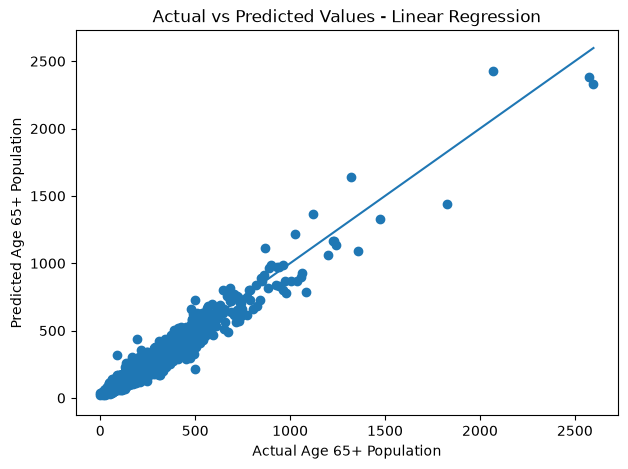

In [60]:
# Create a scatter plot for Linear Regression
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    linear_predictions
)

# Add a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

# Add title and labels
plt.title('Actual vs Predicted Values - Linear Regression')
plt.xlabel('Actual Age 65+ Population')
plt.ylabel('Predicted Age 65+ Population')

# Display the chart
plt.show()

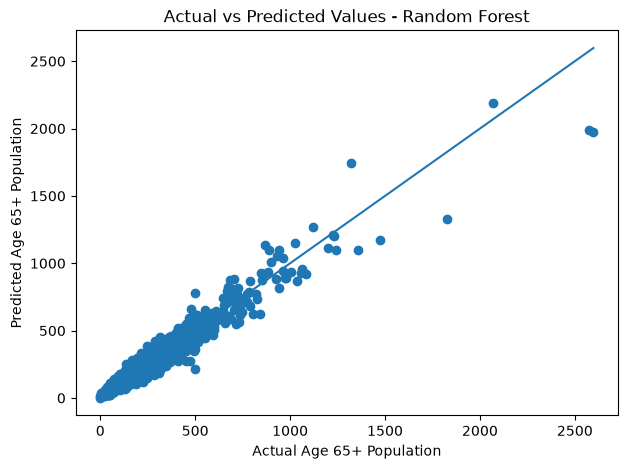

In [61]:
# Create a scatter plot for Random Forest Regression
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    random_forest_predictions
)

# Add a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

# Add title and labels
plt.title('Actual vs Predicted Values - Random Forest')
plt.xlabel('Actual Age 65+ Population')
plt.ylabel('Predicted Age 65+ Population')

# Display the chart
plt.show()

## Feature Importance

In [70]:
# Get the coefficients of each feature
feature_coefficients = linear_model.coef_

# Create a DataFrame with feature names and coefficient values
importance_data = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': feature_coefficients
})

# Calculate absolute coefficient values
importance_data['Absolute_Importance'] = abs(
    importance_data['Importance']
)

# Sort features by absolute importance
importance_data = importance_data.sort_values(
    by='Absolute_Importance',
    ascending=False
)

# Display the feature importance
importance_data

,Feature,Importance,Absolute_Importance
4,Age_60_64,142.792620,142.792620
2,Age_0_14,-43.781283,43.781283
3,Age_15_59,42.420309,42.420309
0,Province_Name,8.046706,8.046706
1,District_Name,3.425820,3.425820


In [77]:
# Calculate percentage importance
importance_data['Importance_Percentage'] = (
    importance_data['Absolute_Importance']
    / importance_data['Absolute_Importance'].sum()
) * 100

print(importance_data)

         Feature  Importance  Absolute_Importance  Importance_Percentage
4      Age_60_64  142.792620           142.792620              59.381443
2       Age_0_14  -43.781283            43.781283              18.206794
3      Age_15_59   42.420309            42.420309              17.640822
0  Province_Name    8.046706             8.046706               3.346286
1  District_Name    3.425820             3.425820               1.424655


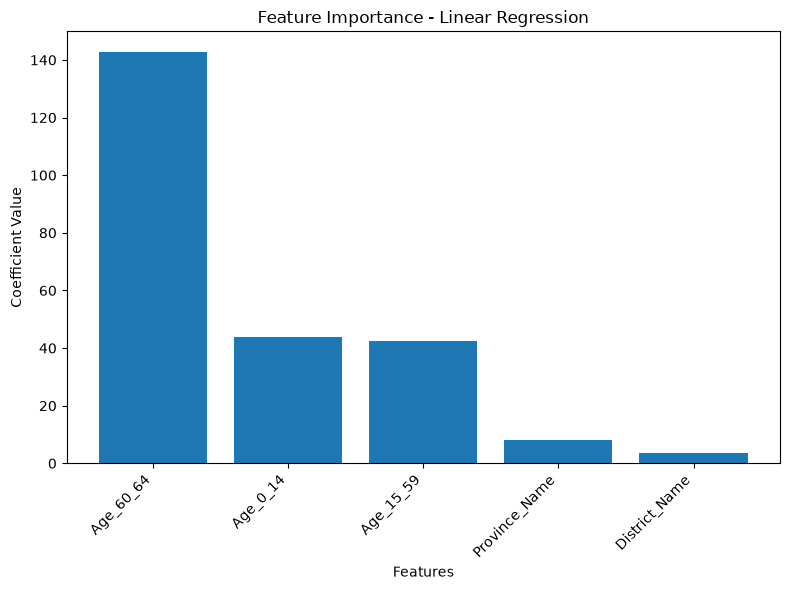

In [76]:
# Create a bar chart of feature coefficients
plt.figure(figsize=(8, 6))

plt.bar(
    importance_data['Feature'],
    importance_data['Absolute_Importance']
)

# Add title and labels
plt.title('Feature Importance - Linear Regression')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')

# Rotate feature names
plt.xticks(rotation=45, ha='right')

# Display the chart
plt.tight_layout()
plt.show()

## Final Model Evaluation

In [74]:
# Display the final model evaluation results
model_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,28.892878,1836.239382,42.851364,0.937678
1,Random Forest Regression,26.873185,1867.096532,43.209912,0.936631
